# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/M-Abdullah-Nazeer/Flyrank-Ml-Pipeline/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [1]:
!pip -q install duckdb
import duckdb, os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import userdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
rel = "hf://datasets/FlyRank/internship-warehouse"
os.makedirs("work/outputs", exist_ok=True)

In [2]:
def build_month(m):
    con.sql(f"""CREATE OR REPLACE TABLE dm AS
      SELECT * FROM read_parquet('{rel}/fact_content_daily_performance/month={m}/*.parquet')""")
    df = con.sql("""
    WITH past AS (
      SELECT client_hash_id, content_hash_id,
             SUM(gsc_impressions) AS impressions, SUM(gsc_clicks) AS clicks,
             SUM(gsc_avg_position * gsc_impressions) / NULLIF(SUM(gsc_impressions), 0) AS position,
             COUNT(*) AS days_with_data,
             SUM(CASE WHEN day(report_date) BETWEEN 8 AND 15 THEN gsc_impressions END) AS impr_late,
             SUM(CASE WHEN day(report_date) BETWEEN 1 AND 7 THEN gsc_impressions END) AS impr_early
      FROM dm WHERE gsc_data_available IS TRUE AND gsc_impressions > 0 AND day(report_date) <= 15
      GROUP BY 1, 2),
    fut AS (
      SELECT client_hash_id, content_hash_id, SUM(gsc_impressions) AS f_impr, SUM(gsc_clicks) AS f_clicks
      FROM dm WHERE gsc_data_available IS TRUE AND day(report_date) > 15
      GROUP BY 1, 2)
    SELECT p.*, f.f_impr, f.f_clicks FROM past p LEFT JOIN fut f USING (client_hash_id, content_hash_id)
    """).df()
    df["month"] = m
    return df

TRAIN_MONTHS, QUEUE_MONTH = ["2026-02", "2026-03"], "2026-04"
assert "2026-06" not in TRAIN_MONTHS + [QUEUE_MONTH]          # sealed month stays untouched
raw = {m: build_month(m) for m in TRAIN_MONTHS + [QUEUE_MONTH]}

past_ok = lambda d: d[(d["impressions"] >= 100) & (d["position"] <= 20)].copy()      # past-only eligibility
train = past_ok(pd.concat([raw[m] for m in TRAIN_MONTHS], ignore_index=True))
train = train[train["f_impr"] >= 100].copy()                  # training needs a measurable label
queue = past_ok(raw[QUEUE_MONTH])                             # the queue never looks at days 16+

bins, labs = [0, 3, 6, 10, 20], ["1-3", "4-6", "7-10", "11-20"]
tb = pd.cut(train["position"], bins, labels=labs)
expected = (train.groupby(tb, observed=True)["clicks"].sum() /
            train.groupby(tb, observed=True)["impressions"].sum()).to_dict()   # training months only

def add_cols(df):
    df["pos_bucket"] = pd.cut(df["position"], bins, labels=labs)
    df["expected_ctr"] = df["pos_bucket"].map(expected).astype(float)
    df["ctr"] = df["clicks"] / df["impressions"]
    df["log_impr"] = np.log10(df["impressions"])
    df["ctr_gap_ratio"] = (df["ctr"] / df["expected_ctr"]).clip(upper=10)
    df["trend_ratio"] = (df["impr_late"] / df["impr_early"]).replace([np.inf, -np.inf], np.nan).clip(upper=10)
    df["missed_clicks"] = (df["impressions"] * (df["expected_ctr"] - df["ctr"])).clip(lower=0)   # size proxy, days 1-15
    # label (used only for training and for checking the queue afterwards)
    df["label"] = np.where(df["f_impr"] >= 100, (df["f_clicks"] < 0.5 * df["f_impr"] * df["expected_ctr"]).astype(float), np.nan)
    return df

train, queue = add_cols(train), add_cols(queue)
FEATURES = ["log_impr", "position", "ctr", "ctr_gap_ratio", "trend_ratio", "days_with_data"]
model = HistGradientBoostingClassifier(random_state=0).fit(train[FEATURES], train["label"])
queue["model_score"] = model.predict_proba(queue[FEATURES])[:, 1]
queue["priority"] = queue["model_score"] * queue["missed_clicks"]       # risk x size
print("train", train.shape, "| queue pages", queue.shape, "| labelled for checking:", int(queue["label"].notna().sum()))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train (105942, 19) | queue pages (68176, 21) | labelled for checking: 59986


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**Ranked actions:** pages are ranked by `priority = model_score × missed_clicks`, where `model_score` is the gradient-boosting probability that a page keeps under-capturing clicks (validated in Weeks 5-6) and `missed_clicks` is impressions × (expected CTR − actual CTR) in days 1-15, a size proxy. Each page gets one reason code and one action:
- `DECLINING_AND_UNDER_CLICKED`: review for refresh, then fix the snippet.
- `UNDER_CLICKED_TOP3_CHECK_SERP`: check SERP features first (in Week 6 the top-3 bucket had the highest wrong rate, 13.5%).
- `UNDER_CLICKED_PAGE1_REWRITE_SNIPPET`: rewrite title and meta description.
- `STRIKING_DISTANCE_UNDER_CLICKED`: improve snippet and content depth.

**Archetype → action:** rule-based groups from days 1-15, with the share of April pages and the observed under-capture rate in days 16+ (checked pages only):

| Archetype | Share of pages | Observed under-capture rate | Action |
|---|---|---|---|
| Visible but under-clicked | 36.4% | 0.661 (n = 21,367) | Rewrite snippet |
| Over-performer | 20.9% | 0.204 (n = 13,027) | Protect: leave alone, monitor |
| Striking distance | 17.5% | 0.663 (n = 10,382) | Improve |
| On par | 17.0% | 0.299 (n = 11,443) | Monitor |
| Slipping | 8.3% | 0.714 (n = 3,767) | Refresh review |

The groups are defined from the same features the model uses, so these rates describe the groups and are not independent evidence. Even the over-performer group under-captured about 20% of the time later, so "protect" means "don't rewrite by default", not "never look".

**Decay / refresh insight:** pages with a shrinking impression trend in days 1-15 had an observed under-capture rate of 0.668 (n = 4,393), against 0.488 for flat pages (n = 30,254) and 0.489 for growing pages (n = 23,713). So a falling trend adds about 18 points of risk, while growth gives no protection. This is directional: my data has no page age or update date, so I cannot test a time-since-refresh effect or claim that a refresh would help. FlyRank's April 2026 report links older pages with weaker results and recommends reviewing pages before the 9-12 month mark, which I treat as a hypothesis for the review rules, not something I tested.

**What the top of the queue looks like:** all of the top 10 are pages with 5,000+ impressions, because `priority` multiplies risk by size. The top 500 contain 324 page-1 snippet rewrites, 116 top-3 SERP checks, 44 declining pages and 16 striking-distance pages. Almost a quarter of the top 500 (116 pages) are top-3 pages, the group with the highest wrong rate in Week 6, so those need the SERP check before any edit.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
ACTIONS = {
 "DECLINING_AND_UNDER_CLICKED": ("Review for refresh, then fix snippet", "Impressions fell during the window AND CTR is below expected"),
 "UNDER_CLICKED_TOP3_CHECK_SERP": ("Check SERP features first; test title/meta only if none", "Top-3 page with CTR far below expected"),
 "UNDER_CLICKED_PAGE1_REWRITE_SNIPPET": ("Rewrite title and meta description", "Page 1 (4-10) with CTR far below expected"),
 "STRIKING_DISTANCE_UNDER_CLICKED": ("Improve snippet and content depth", "Position 11-20 with CTR below expected"),
}
def reason(r):
    if r["trend_ratio"] < 0.7 and r["ctr_gap_ratio"] < 0.8: return "DECLINING_AND_UNDER_CLICKED"
    if r["position"] <= 3: return "UNDER_CLICKED_TOP3_CHECK_SERP"
    if r["position"] <= 10: return "UNDER_CLICKED_PAGE1_REWRITE_SNIPPET"
    return "STRIKING_DISTANCE_UNDER_CLICKED"

q = queue[(queue["priority"] > 0) & (queue["ctr_gap_ratio"] < 0.8)].sort_values("priority", ascending=False).reset_index(drop=True)
q["rank"] = q.index + 1
q["reason_code"] = q.apply(reason, axis=1)
q["action"] = q["reason_code"].map(lambda c: ACTIONS[c][0])
q["volume_bucket"] = pd.cut(q["impressions"], [0, 300, 1000, 5000, 1e12], labels=["100-300", "300-1k", "1k-5k", "5k+"])

print("pages in queue:", len(q))
display(q.head(10)[["rank", "reason_code", "action", "pos_bucket", "volume_bucket", "model_score", "priority"]].round(3))
display(q.head(500).groupby("reason_code").size().rename("pages in top 500").to_frame())

# Archetypes (rule-based, from days 1-15 only; not machine-learned clusters)
def archetype(r):
    if r["ctr_gap_ratio"] >= 1.2: return "Over-performer"
    if r["trend_ratio"] < 0.7: return "Slipping"
    if r["ctr_gap_ratio"] < 0.5 and r["position"] <= 10: return "Visible but under-clicked"
    if r["position"] > 10: return "Striking distance"
    return "On par"
ARCH_ACTION = {"Over-performer": "Protect: leave alone, monitor", "Slipping": "Refresh review",
               "Visible but under-clicked": "Rewrite snippet", "Striking distance": "Improve",
               "On par": "Monitor"}
queue["archetype"] = queue.apply(archetype, axis=1)
arch = queue.groupby("archetype").agg(pages=("ctr", "size"), share=("ctr", lambda s: round(len(s) / len(queue), 3)),
                                      under_capture_rate=("label", "mean"), checked_n=("label", "count")).round(3)
arch["action"] = arch.index.map(ARCH_ACTION)
display(arch)

# Decay insight: does a falling impression trend raise the risk? (trend grouped from days 1-15; label from days 16+)
queue["trend_bucket"] = pd.cut(queue["trend_ratio"], [-0.01, 0.7, 1.3, 1e9], labels=["shrinking", "flat", "growing"])
decay = queue.groupby("trend_bucket", observed=True).agg(pages=("ctr", "size"), under_capture_rate=("label", "mean"),
                                                         checked_n=("label", "count")).round(3)
display(decay)

pages in queue: 46330


,rank,reason_code,action,pos_bucket,volume_bucket,model_score,priority
0,1,DECLINING_AND_UNDER_CLICKED,"Review for refresh, then fix snippet",1-3,5k+,0.945,563.318
1,2,STRIKING_DISTANCE_UNDER_CLICKED,Improve snippet and content depth,11-20,5k+,0.951,499.167
2,3,DECLINING_AND_UNDER_CLICKED,"Review for refresh, then fix snippet",1-3,5k+,0.894,441.392
3,4,UNDER_CLICKED_TOP3_CHECK_SERP,Check SERP features first; test title/meta onl...,1-3,5k+,0.935,376.068
4,5,UNDER_CLICKED_PAGE1_REWRITE_SNIPPET,Rewrite title and meta description,7-10,5k+,0.949,299.580
5,6,DECLINING_AND_UNDER_CLICKED,"Review for refresh, then fix snippet",1-3,5k+,0.894,271.882
6,7,UNDER_CLICKED_PAGE1_REWRITE_SNIPPET,Rewrite title and meta description,4-6,5k+,0.869,250.649
7,8,UNDER_CLICKED_PAGE1_REWRITE_SNIPPET,Rewrite title and meta description,4-6,5k+,0.929,241.068
8,9,DECLINING_AND_UNDER_CLICKED,"Review for refresh, then fix snippet",4-6,5k+,0.916,236.826
9,10,UNDER_CLICKED_TOP3_CHECK_SERP,Check SERP features first; test title/meta onl...,1-3,5k+,0.669,200.144


,pages in top 500
reason_code,
DECLINING_AND_UNDER_CLICKED,44
STRIKING_DISTANCE_UNDER_CLICKED,16
UNDER_CLICKED_PAGE1_REWRITE_SNIPPET,324
UNDER_CLICKED_TOP3_CHECK_SERP,116


,pages,share,under_capture_rate,checked_n,action
archetype,,,,,
On par,11568,0.170,0.299,11443,Monitor
Over-performer,14236,0.209,0.204,13027,"Protect: leave alone, monitor"
Slipping,5627,0.083,0.714,3767,Refresh review
Striking distance,11926,0.175,0.663,10382,Improve
Visible but under-clicked,24819,0.364,0.661,21367,Rewrite snippet


,pages,under_capture_rate,checked_n
trend_bucket,,,
shrinking,6523,0.668,4393
flat,33860,0.488,30254
growing,26069,0.489,23713


In [4]:
MINUTES_PER_PAGE = 20          # ASSUMPTION: a human review takes about 20 minutes; change it to your own estimate
chk = q[q["label"].notna()]
rows = []
for k in [100, 250, 500, 1000]:
    top = q.head(k); ck = chk[chk["rank"] <= k]
    hours = k * MINUTES_PER_PAGE / 60
    rows.append({"top_k": k, "review_hours (assumed)": round(hours, 1),
                 "missed clicks, days 1-15 (proxy)": int(top["missed_clicks"].sum()),
                 "missed clicks per review hour": round(top["missed_clicks"].sum() / hours, 1),
                 "observed under-capture rate (checked pages)": round(ck["label"].mean(), 3)})
cost_value = pd.DataFrame(rows)
display(cost_value)

,top_k,review_hours (assumed),"missed clicks, days 1-15 (proxy)",missed clicks per review hour,observed under-capture rate (checked pages)
0,100,33.3,14199,426.0,0.890
1,250,83.3,23220,278.6,0.880
2,500,166.7,33973,203.8,0.853
3,1000,333.3,48773,146.3,0.839


**Cost/value:** review time is an assumption (20 minutes a page, adjustable) and value is a click proxy for days 1-15, not revenue.

| Top k | Review hours (assumed) | Missed clicks, days 1-15 | Missed clicks per review hour | Observed under-capture rate |
|---|---|---|---|---|
| 100 | 33.3 | 14,199 | 426 | 0.890 |
| 250 | 83.3 | 23,220 | 279 | 0.880 |
| 500 | 166.7 | 33,973 | 204 | 0.853 |
| 1,000 | 333.3 | 48,773 | 146 | 0.839 |

The value per review hour falls by about two thirds between the top 100 and the top 1,000 (426 to 146), while the under-capture rate falls only from 0.890 to 0.839. So returns shrink mainly because lower-ranked pages are smaller, not because the model gets much less accurate. A team should start at the top and stop where the extra hours are no longer worth it to them. These are decision-support numbers, not a forecast of clicks gained.

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use:** a content or SEO analyst uses the queue to decide which already-visible pages (at least 100 impressions in the half-month, average position 20 or better) to review first for snippet, content or refresh work. It is a prioritisation aid for human review, not an automatic editor.
**Where it is valid:** pages like the ones it was built on: Search Console data, positions 1-20, one half-month of history, trained on Feb-Mar 2026 and checked on Apr 2026.
**Limits:**
- It ranks pages likely to keep getting fewer clicks than expected for their position. It does not show why, and it does not show that a rewrite or refresh would raise clicks (observed association, not cause).
- Held-out later month and unseen clients keep a lead over the simple rule (Week 6, split D: precision@500 0.898 vs 0.778), but that check used one draw of 7,657 pages, so I read it as directional.
- The label is a cut-off I chose (under 50% of expected clicks), so some "wrong" picks are near misses.
- Top-3 pages have the most wrong picks (13.5%), likely because search features can take the click.
- Pages with sudden later drops are invisible to these features (the Week 6 false negatives).
- No page age or update date, so no test of time-since-refresh.
- Expected CTR comes from my own position-bucket curve, which is only roughly monotonic.

- The queue ranks by risk × size, so its top 500 pages had an observed under-capture rate of 0.853, below the 0.924 reached when ranking by model score alone. Putting big pages first costs some precision.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Before acting on any pick, a person checks:**
1. Is the page's search result affected by a feature (featured snippet, ads, AI answer) rather than the title?
2. Is the low CTR a near miss or a clear case (how far below expected)?
3. Did position or impressions move sharply during the window (use the reason code `DECLINING_...`)?
4. Does the page's intent match the queries it ranks for?
5. Does the change keep facts, brand voice and compliance requirements intact?

**What should NOT be automated:**
- Publishing any title, meta or body change without human approval.
- Deleting, merging or redirecting pages based on this queue (it has no age, backlink or conversion data).
- Acting on top-3 pages without the SERP check.
- Telling clients a rewrite "will" raise clicks, or reporting the queue as proof of cause.
- Using hash ids, domains or queries in anything public.
- Running it on pages below 100 impressions, positions beyond 20, or other data sources, where it was never validated.
- Retiring human review once the model looks good.

In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**Monitoring (light, non-production):** each month, after days 16+ arrive, re-run the table above on the newest month. The "now" values for April are the reference point (precision@500 0.924 by model score, AUC 0.789, label-rate shift -0.018, PSI 0.043 for `ctr_gap_ratio` and 0.015 for `position`); none is near a trigger. The thresholds are my proposals and not tested rules.
- **Retrain** if precision@500 falls below base rate + 0.15 (below 0.647 on the April base rate of 0.497), if AUC falls below 0.70, or if the label rate moves more than 0.10 from training.
- **Recompute the expected-CTR curve** if the PSI for `ctr_gap_ratio` or `position` goes above 0.25, which would mean the pages or the search results have shifted.
- **Stop using the queue and investigate** if reviewers regularly reject the top picks, or a search-feature or Google change is known.
- **Re-check after adding new clients**, since unseen clients were the weakest validation point.
- **Track the queue's own precision** (0.853 at the top 500 for April), since that is what reviewers see.

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def psi(a, b, bins=10):
    a, b = a.dropna(), b.dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    ca = np.histogram(a, edges)[0] / len(a) + 1e-6
    cb = np.histogram(np.clip(b, edges[0], edges[-1]), edges)[0] / len(b) + 1e-6
    return float(np.sum((cb - ca) * np.log(cb / ca)))

labelled = queue[queue["label"].notna()].sort_values("model_score", ascending=False)
top500 = labelled.head(500)
mon = pd.DataFrame([
  {"signal": "precision@500 on newest month", "now": round(top500["label"].mean(), 3), "trigger": "below base rate + 0.15", "base_rate": round(labelled["label"].mean(), 3)},
  {"signal": "AUC on newest month", "now": round(roc_auc_score(labelled["label"], labelled["model_score"]), 3), "trigger": "below 0.70", "base_rate": None},
  {"signal": "label rate shift vs training", "now": round(labelled["label"].mean() - train["label"].mean(), 3), "trigger": "absolute shift above 0.10", "base_rate": None},
  {"signal": "PSI: ctr_gap_ratio", "now": round(psi(train["ctr_gap_ratio"], queue["ctr_gap_ratio"]), 3), "trigger": "above 0.25", "base_rate": None},
  {"signal": "PSI: position", "now": round(psi(train["position"], queue["position"]), 3), "trigger": "above 0.25", "base_rate": None},
])
display(mon)

,signal,now,trigger,base_rate
0,precision@500 on newest month,0.924,below base rate + 0.15,0.497
1,AUC on newest month,0.789,below 0.70,NaN
2,label rate shift vs training,-0.018,absolute shift above 0.10,NaN
3,PSI: ctr_gap_ratio,0.043,above 0.25,NaN
4,PSI: position,0.015,above 0.25,NaN


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

**Exports for the paper** (all in `work/outputs/`): `w07_ranked_queue.csv` (top 1,000 pages with rank, reason code, action, position and volume buckets, model score and priority; no ids and no exact counts, to respect the data terms), `w07_playbook_actions.csv`, `w07_archetypes.csv`, `w07_decay_by_trend.csv`, `w07_cost_value.csv`, `w07_monitoring.csv`, and two figures (`w07_fig_queue_by_reason.png`, `w07_fig_cumulative_missed.png`). Earlier outputs from w05 and w06 (`w05_model_vs_baseline.csv`, `w06_before_after.csv`) cover the Results section.

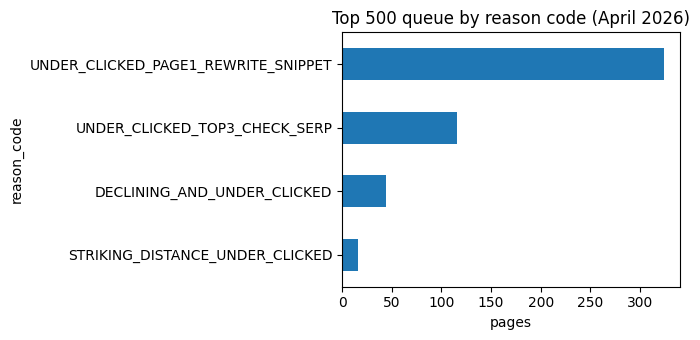

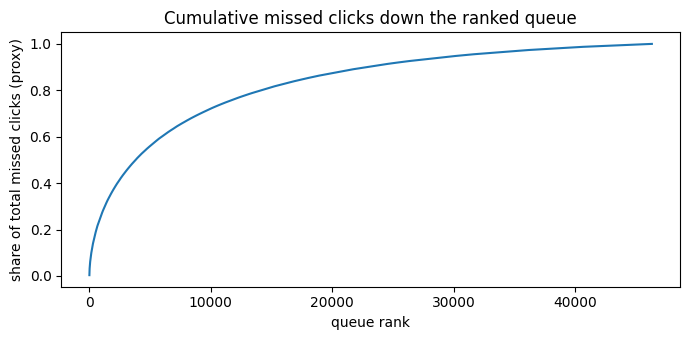

['w07_archetypes.csv', 'w07_cost_value.csv', 'w07_decay_by_trend.csv', 'w07_fig_cumulative_missed.png', 'w07_fig_queue_by_reason.png', 'w07_monitoring.csv', 'w07_playbook_actions.csv', 'w07_ranked_queue.csv']


In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
export = q.head(1000)[["rank", "reason_code", "action", "pos_bucket", "volume_bucket", "model_score", "priority"]].copy()
export["model_score"] = export["model_score"].round(3); export["priority"] = export["priority"].round(1)
export.rename(columns={"pos_bucket": "position_bucket"}).to_csv("work/outputs/w07_ranked_queue.csv", index=False)   # no ids, no exact counts

playbook = pd.DataFrame([{"reason_code": c, "action": a, "meaning": m} for c, (a, m) in ACTIONS.items()])
playbook.to_csv("work/outputs/w07_playbook_actions.csv", index=False)
arch.reset_index().to_csv("work/outputs/w07_archetypes.csv", index=False)
decay.reset_index().to_csv("work/outputs/w07_decay_by_trend.csv", index=False)
cost_value.to_csv("work/outputs/w07_cost_value.csv", index=False)
mon.to_csv("work/outputs/w07_monitoring.csv", index=False)

# Figure 1: queue composition
fig, ax = plt.subplots(figsize=(7, 3.5))
q.head(500)["reason_code"].value_counts().sort_values().plot.barh(ax=ax)
ax.set_title("Top 500 queue by reason code (April 2026)"); ax.set_xlabel("pages")
plt.tight_layout(); plt.savefig("work/outputs/w07_fig_queue_by_reason.png", dpi=150); plt.show()

# Figure 2: how fast the missed-click proxy accumulates down the queue
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(q["rank"], q["missed_clicks"].cumsum() / q["missed_clicks"].sum())
ax.set_xlabel("queue rank"); ax.set_ylabel("share of total missed clicks (proxy)")
ax.set_title("Cumulative missed clicks down the ranked queue")
plt.tight_layout(); plt.savefig("work/outputs/w07_fig_cumulative_missed.png", dpi=150); plt.show()
print(sorted(os.listdir("work/outputs")))

**Exports for the paper** (all in `work/outputs/`): `w07_ranked_queue.csv` (top 1,000 pages with rank, reason code, action, position and volume buckets, model score and priority; no ids and no exact counts, to respect the data terms), `w07_playbook_actions.csv`, `w07_archetypes.csv`, `w07_decay_by_trend.csv`, `w07_cost_value.csv`, `w07_monitoring.csv`, and two figures (`w07_fig_queue_by_reason.png`, `w07_fig_cumulative_missed.png`). Earlier outputs from w05 and w06 (`w05_model_vs_baseline.csv`, `w06_before_after.csv`) cover the Results section.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.